In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch    
import torch.nn as nn
import torchvision
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.sparse import hstack, csr_matrix

np.random.seed(42)
torch.manual_seed(42)

CSV_PATH = 'train.csv'
IMG_DIR = 'train/train/'

In [2]:
df = pd.read_csv(CSV_PATH)

print(df.shape)
print(df.isna().sum())
df.head()

(46229, 4)
ImgId             0
title             1
description    1042
categories        0
dtype: int64


,ImgId,title,description,categories
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing"
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry"
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care


In [3]:
df['has_image'] = df['ImgId'].apply(lambda x: os.path.exists(IMG_DIR + x + '.jpg'))
print(df['has_image'].sum(), 'з', len(df))

df = df[df['has_image']].reset_index(drop=True)

df['title'] = df['title'].fillna('')
df['description'] = df['description'].fillna('')
df['text'] = df['title'] + '. ' + df['description']
df['n_words'] = df['text'].str.split().str.len()

print(df.shape)
print('дублікатів:', df['text'].duplicated().sum())
print(df['n_words'].describe())

42000 з 46229
(42000, 7)
дублікатів: 214
count    42000.000000
mean        82.321643
std         93.006509
min          1.000000
25%         29.000000
50%         57.000000
75%        102.000000
max       1958.000000
Name: n_words, dtype: float64


categories
Arts, Crafts & Sewing        2000
Cell Phones & Accessories    2000
Clothing, Shoes & Jewelry    2000
Tools & Home Improvement     2000
Health & Personal Care       2000
Baby Products                2000
Baby                         2000
Patio, Lawn & Garden         2000
Beauty                       2000
Sports & Outdoors            2000
Electronics                  2000
All Electronics              2000
Automotive                   2000
Toys & Games                 2000
All Beauty                   2000
Office Products              2000
Appliances                   2000
Musical Instruments          2000
Industrial & Scientific      2000
Grocery & Gourmet Food       2000
Pet Supplies                 2000
Name: count, dtype: int64


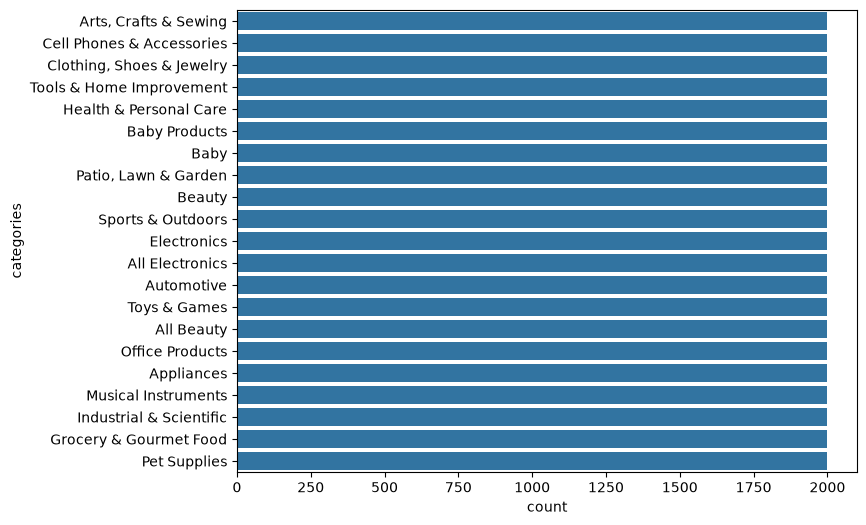

In [4]:
print(df['categories'].value_counts())

plt.figure(figsize=(8, 6))
sns.countplot(y='categories', data=df, order=df['categories'].value_counts().index)
plt.show()

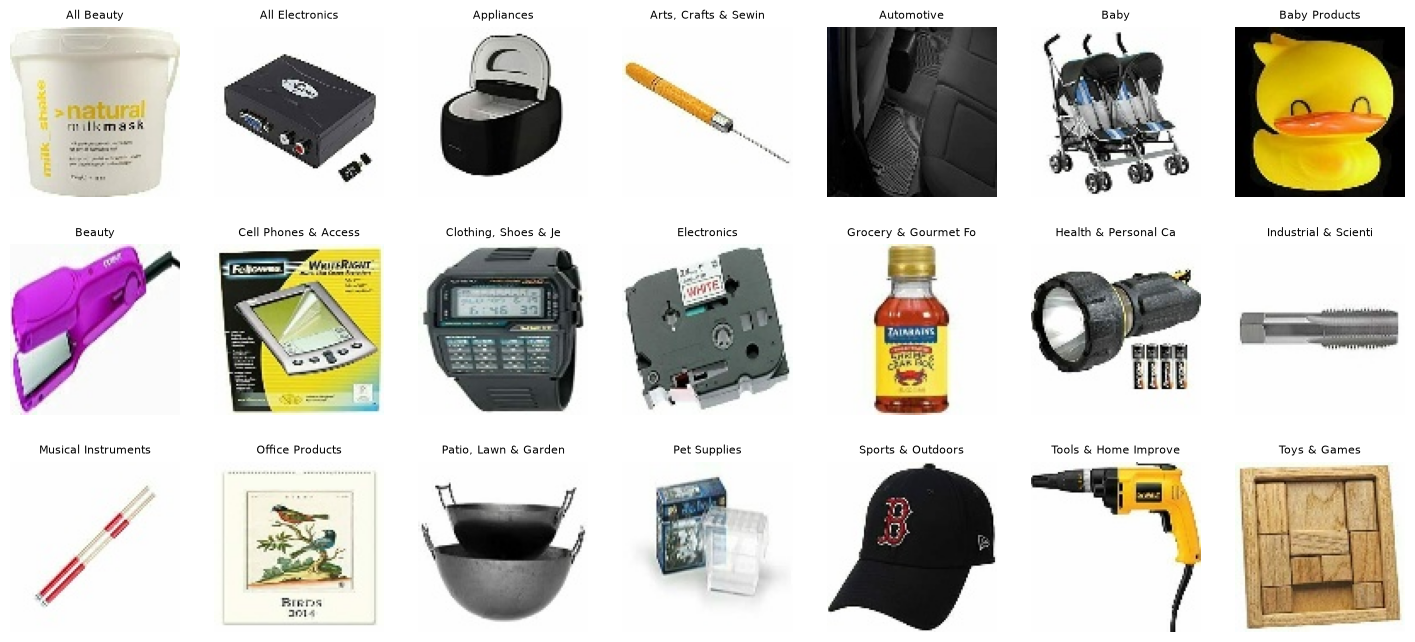

In [5]:
cats = sorted(df['categories'].unique())

plt.figure(figsize=(18, 8))
for i in range(len(cats)):
    row = df[df['categories'] == cats[i]].iloc[0]
    plt.subplot(3, 7, i + 1)
    plt.imshow(Image.open(IMG_DIR + row['ImgId'] + '.jpg'))
    plt.title(cats[i][:20], fontsize=8)
    plt.axis('off')
plt.show()

In [6]:
for i in range(3):
    row = df.iloc[i]
    print(row['categories'])
    print(row['title'])
    print(row['description'][:200])
    print('-----')

Arts, Crafts & Sewing
TUNGSTEN SOLDER PICK WITH HANDLE
Solder Pick for picking up molten solder when making jewelry
-----
Cell Phones & Accessories
Write Right 98167 Screen Protector for Sony T615C
We all screen. And we all need to protect those screens on our expensive little gadgetry. Our each is a pack of (12) clear screen protectors, each a generous 2-15/16" x 2-1/4" x .004" thick. They prot
-----
Clothing, Shoes & Jewelry
Casio Mens DBC310-1 Databank 300 Digital Watch (Discontinued by Manufacturer)
Bringing you precision at a glance, the Casio Men's Databank Digital Watch #DBC310-1 features a blue-tone digital dial face with a durable mineral dial window. An auto-calendar displays the date and m
-----


In [7]:
le = LabelEncoder()
y = le.fit_transform(df['categories'])
classes = le.classes_

train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42, stratify=y)

y_train = y[train_idx]
y_val = y[val_idx]

print(len(train_idx), len(val_idx))

33600 8400


In [8]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words='english')

X_train_text = tfidf.fit_transform(df['text'].iloc[train_idx])
X_val_text = tfidf.transform(df['text'].iloc[val_idx])

text_model = LogisticRegression(C=10, max_iter=1000)
text_model.fit(X_train_text, y_train)

pred_text = text_model.predict(X_val_text)
print(accuracy_score(y_val, pred_text))

0.8358333333333333


In [9]:
cnn = torchvision.models.mobilenet_v2(weights=torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1)
cnn.classifier = nn.Identity()
cnn.eval()

transform = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

if os.path.exists('cnn_features.npy'):
    features = np.load('cnn_features.npy')
else:
    features = []
    ids = df['ImgId'].tolist()

    with torch.no_grad():
        for start in range(0, len(ids), 128):
            batch = []
            for img_id in ids[start:start + 128]:
                img = Image.open(IMG_DIR + img_id + '.jpg').convert('RGB')
                batch.append(transform(img))
            batch = torch.stack(batch)
            features.append(cnn(batch).numpy())
            print(start)

    features = np.concatenate(features)
    np.save('cnn_features.npy', features)

print(features.shape)

(42000, 1280)


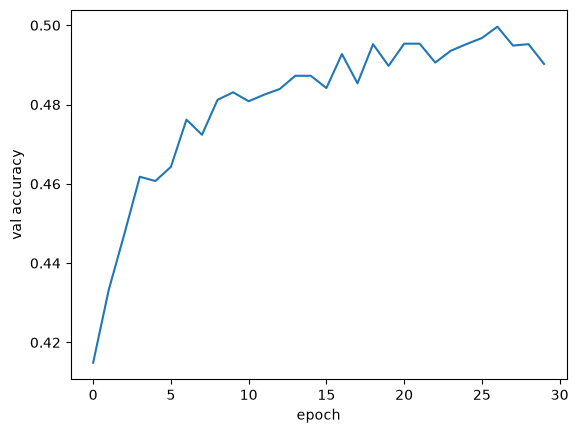

0.49023809523809525


In [10]:
scaler = StandardScaler()
F_train = scaler.fit_transform(features[train_idx])
F_val = scaler.transform(features[val_idx])

F_train_t = torch.tensor(F_train, dtype=torch.float32)
F_val_t = torch.tensor(F_val, dtype=torch.float32)
y_train_t = torch.tensor(y_train)

img_model = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(1280, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, len(classes))
)

optimizer = torch.optim.AdamW(img_model.parameters(), lr=0.001, weight_decay=0.01)
loss_fn = nn.CrossEntropyLoss()

val_acc = []

for epoch in range(30):
    img_model.train()
    perm = torch.randperm(len(F_train_t))

    for start in range(0, len(perm), 256):
        b = perm[start:start + 256]
        optimizer.zero_grad()
        loss = loss_fn(img_model(F_train_t[b]), y_train_t[b])
        loss.backward()
        optimizer.step()

    img_model.eval()
    with torch.no_grad():
        pred_img = img_model(F_val_t).argmax(1).numpy()
    val_acc.append(accuracy_score(y_val, pred_img))

plt.plot(val_acc)
plt.xlabel('epoch')
plt.ylabel('val accuracy')
plt.show()

print(accuracy_score(y_val, pred_img))

In [11]:
w = 0.02

X_train_both = hstack([X_train_text, csr_matrix(F_train * w)]).tocsr()
X_val_both = hstack([X_val_text, csr_matrix(F_val * w)]).tocsr()

both_model = LogisticRegression(C=10, max_iter=300)
both_model.fit(X_train_both, y_train)

pred_both = both_model.predict(X_val_both)
print(accuracy_score(y_val, pred_both))

0.8301190476190476


In [12]:
names = ['Текст', 'Фото', 'Текст + фото']
all_preds = [pred_text, pred_img, pred_both]

results = pd.DataFrame(index=names, columns=['Accuracy', 'Precision', 'Recall', 'F1-score'])

for i in range(3):
    p = all_preds[i]
    results.loc[names[i], 'Accuracy'] = accuracy_score(y_val, p)
    results.loc[names[i], 'Precision'] = precision_score(y_val, p, average='macro', zero_division=0)
    results.loc[names[i], 'Recall'] = recall_score(y_val, p, average='macro', zero_division=0)
    results.loc[names[i], 'F1-score'] = f1_score(y_val, p, average='macro', zero_division=0)

results = results.astype(float).round(4)
results

,Accuracy,Precision,Recall,F1-score
Текст,0.8358,0.8355,0.8358,0.8350
Фото,0.4902,0.4950,0.4902,0.4887
Текст + фото,0.8301,0.8294,0.8301,0.8292


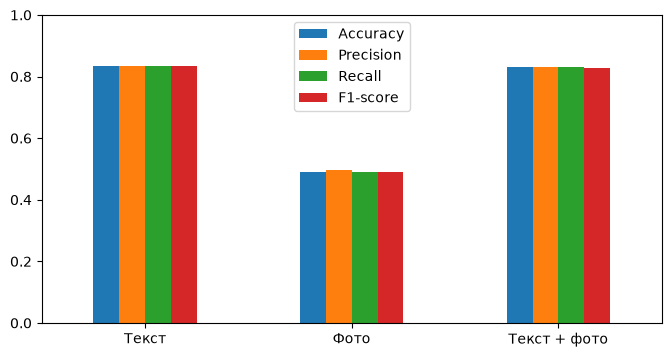

In [13]:
results.plot(kind='bar', figsize=(8, 4), rot=0)
plt.ylim(0, 1)
plt.show()

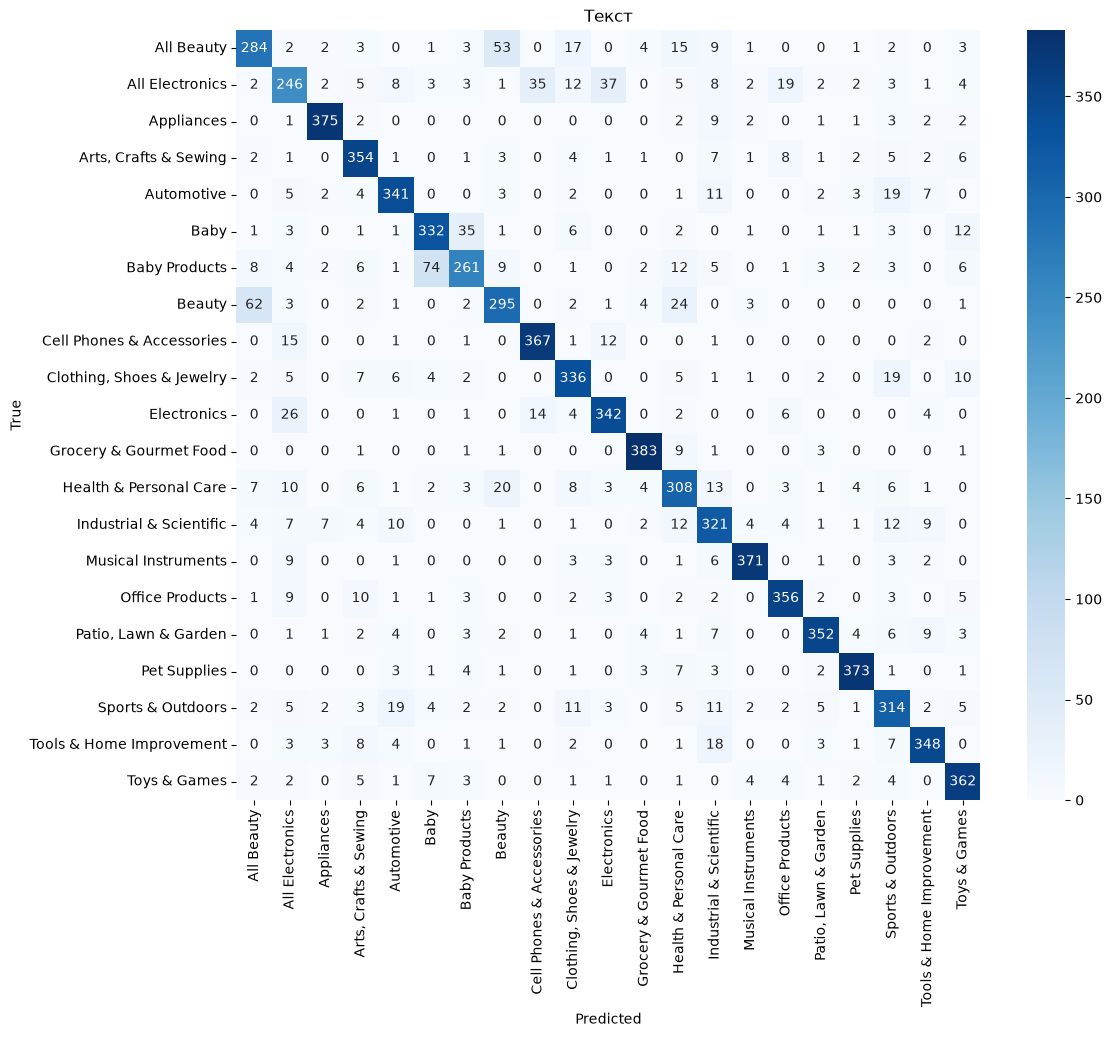

In [14]:
cm = confusion_matrix(y_val, pred_text)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Текст')
plt.show()

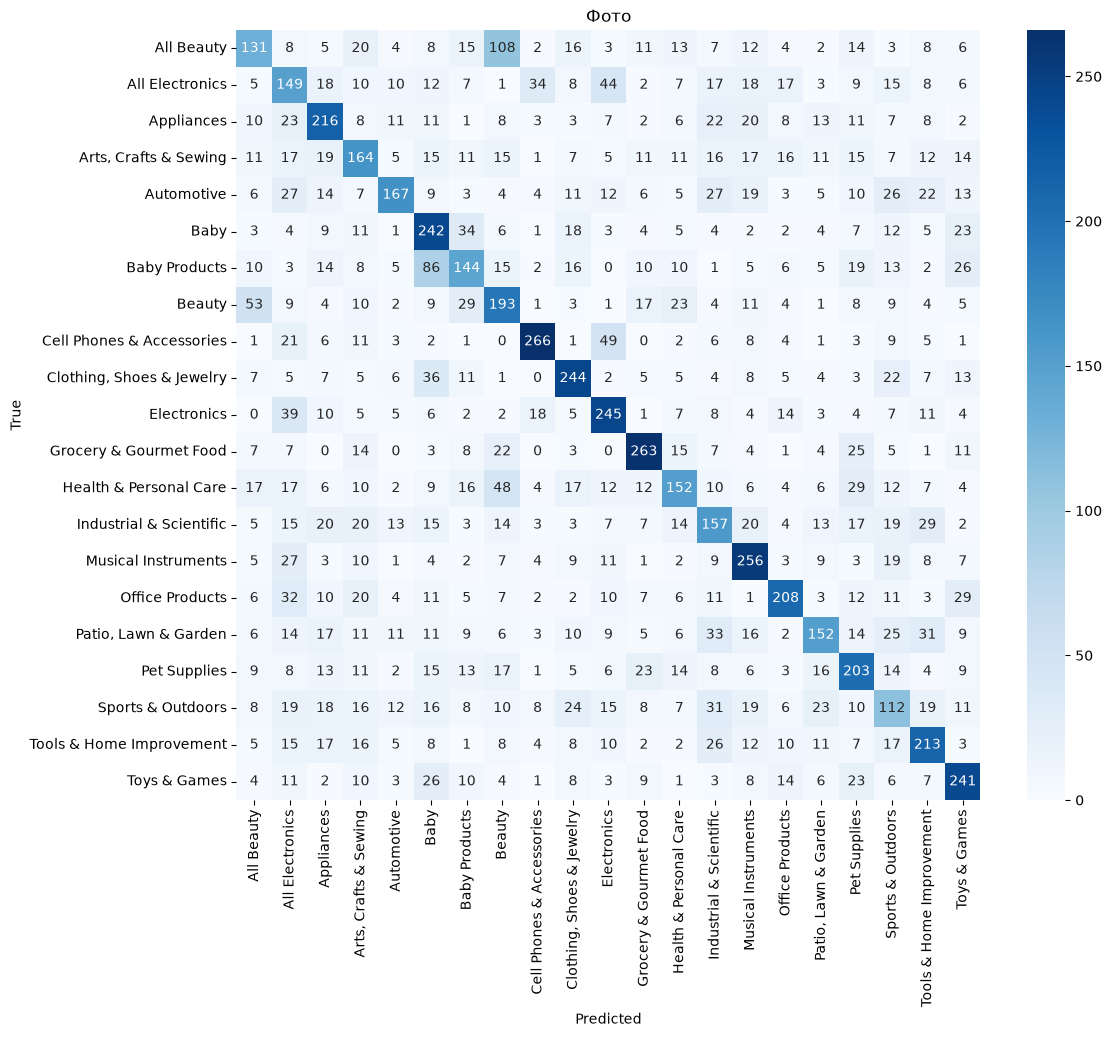

In [15]:
cm = confusion_matrix(y_val, pred_img)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Фото')
plt.show()

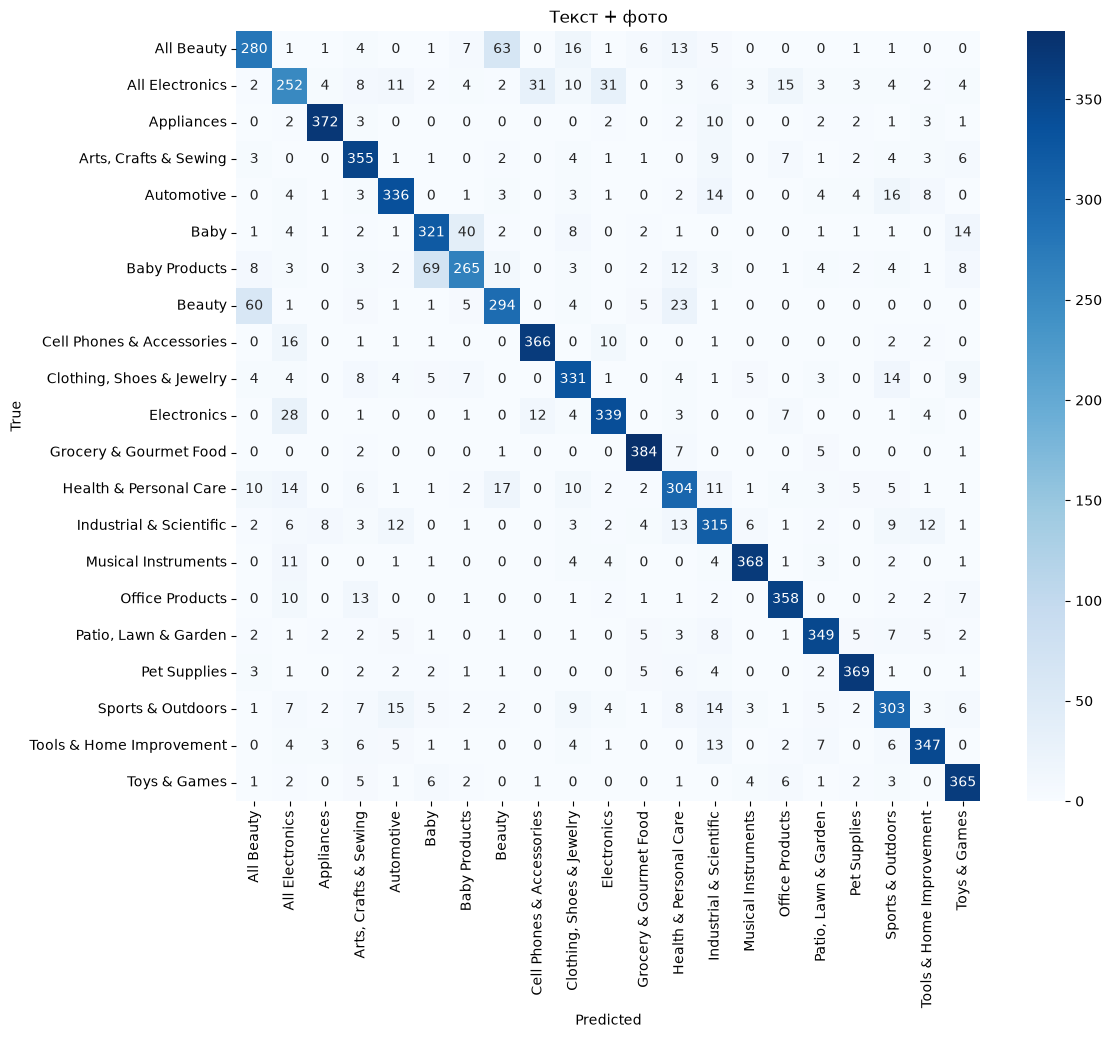

In [16]:
cm = confusion_matrix(y_val, pred_both)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Текст + фото')
plt.show()

In [17]:
text_ok = pred_text == y_val
img_ok = pred_img == y_val
both_ok = pred_both == y_val

print('текст помилився, фото вгадало:', (~text_ok & img_ok).sum())
print('фото помилилось, текст вгадав:', (text_ok & ~img_ok).sum())
print('обидві помилились:', (~text_ok & ~img_ok).sum())
print('обидві помилились, а текст + фото вгадала:', (~text_ok & ~img_ok & both_ok).sum())
print('текст + фото виправила помилки тексту:', (~text_ok & both_ok).sum())
print('текст + фото зламала правильні відповіді тексту:', (text_ok & ~both_ok).sum())

текст помилився, фото вгадало: 314
фото помилилось, текст вгадав: 3217
обидві помилились: 1065
обидві помилились, а текст + фото вгадала: 130
текст + фото виправила помилки тексту: 241
текст + фото зламала правильні відповіді тексту: 289


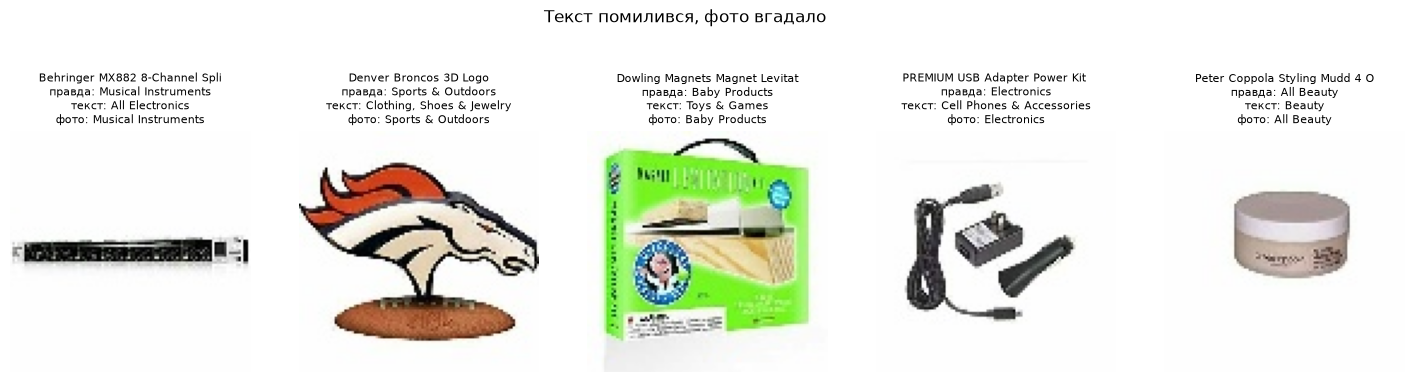

In [18]:
def show_examples(mask, title):
    idx = np.where(mask)[0][:5]

    plt.figure(figsize=(18, 5))
    for i in range(len(idx)):
        k = idx[i]
        row = df.iloc[val_idx[k]]

        plt.subplot(1, 5, i + 1)
        plt.imshow(Image.open(IMG_DIR + row['ImgId'] + '.jpg'))
        plt.axis('off')
        plt.title(row['title'][:30] + '\nправда: ' + row['categories'] + '\nтекст: ' + classes[pred_text[k]] + '\nфото: ' + classes[pred_img[k]], fontsize=8)

    plt.suptitle(title)
    plt.show()


show_examples(~text_ok & img_ok, 'Текст помилився, фото вгадало')

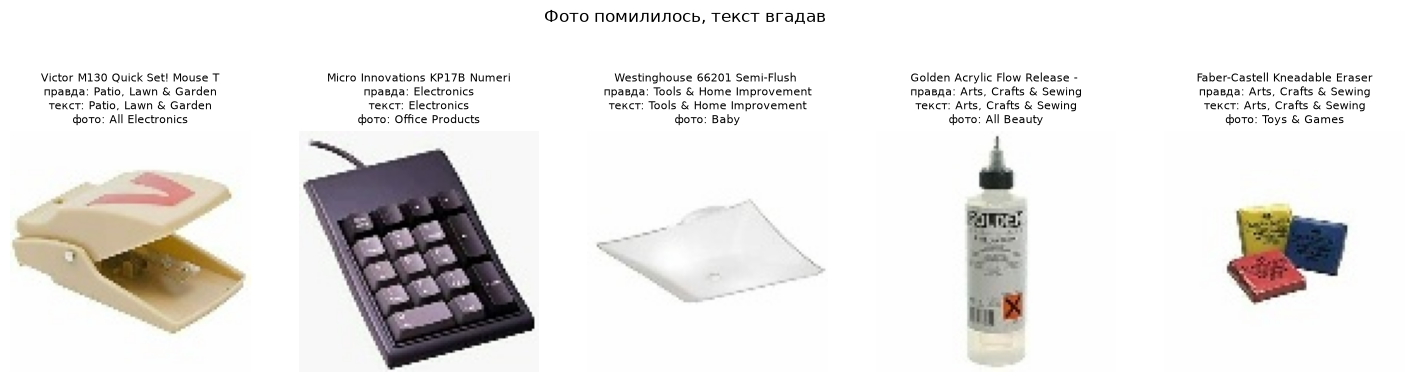

In [19]:
show_examples(text_ok & ~img_ok, 'Фото помилилось, текст вгадав')

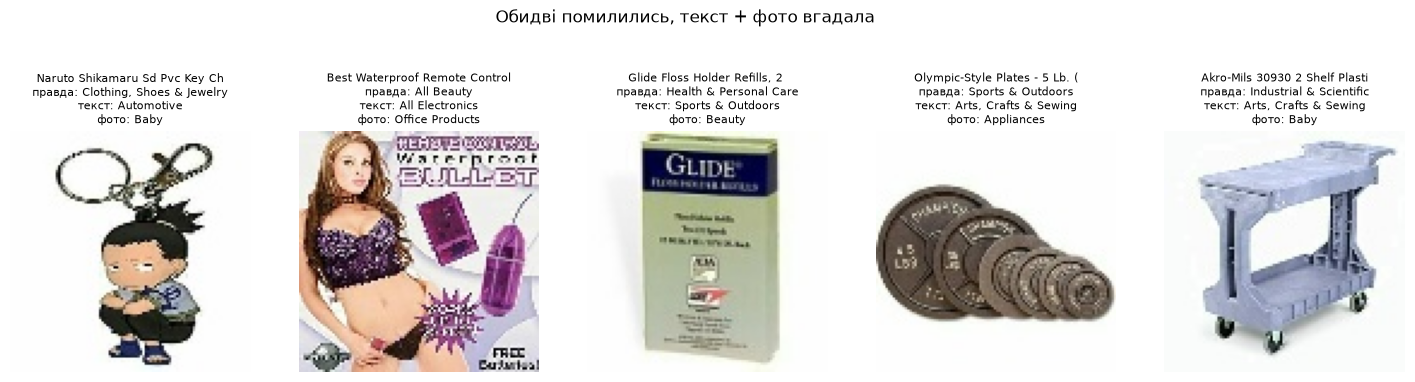

In [20]:
show_examples(~text_ok & ~img_ok & both_ok, 'Обидві помилились, текст + фото вгадала')